In [2]:
import pandas as pd
from datetime import timedelta

# 加载数据集
file_path = 'Online_Retail.xlsx'
df = pd.read_excel(file_path)

# (a) 观察数据，检查缺失值
missing_values = df.isnull().sum()

# (b) 删除 'Description' 特征中的多余空格
df['Description'] = df['Description'].str.strip()

# (c) 删除 'CustomerID' 特征缺失值的交易
df = df.dropna(subset=['CustomerID'])

# (d) 删除已取消的交易（即 'InvoiceNo' 以 'C' 开头的交易）
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# (e) 将 'CustomerID' 特征下的所有值转换为字符串类型
df['CustomerID'] = df['CustomerID'].astype(str)

# (f) 根据以下三个因素分析客户：
# 最近性：自上次购买以来的天数
max_date = df['InvoiceDate'].max() + timedelta(days=1)
df['Recency'] = (max_date - df.groupby('CustomerID')['InvoiceDate'].transform('max')).dt.days

# 频率：交易总次数
df['Frequency'] = df.groupby('CustomerID')['InvoiceNo'].transform('nunique')

# 货币性：交易总金额
df['Monetary'] = df['Quantity'] * df['UnitPrice']
df['Monetary'] = df.groupby('CustomerID')['Monetary'].transform('sum')

# (g) 用 'CustomerID'、'Recency'、'Frequency'、'Monetary' 生成新表
rfm_df = df[['CustomerID', 'Recency', 'Frequency', 'Monetary']].drop_duplicates()

# (h) 使用 scikit-learn 库中的 MinMaxScaler 对数据进行归一化处理
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
rfm_df[['Recency', 'Frequency', 'Monetary']] = scaler.fit_transform(rfm_df[['Recency', 'Frequency', 'Monetary']])

rfm_df.head(), missing_values


(   CustomerID   Recency  Frequency  Monetary
 0     12583.0  0.005391   0.466667  0.226426
 20    12686.0  1.000000   0.000000  0.000491
 27    12682.0  0.008086   1.000000  0.383709
 43    12793.0  0.900270   0.033333  0.014827
 50    12567.0  0.059299   0.300000  0.293019,
 InvoiceNo        0
 StockCode        0
 Description      0
 Quantity         0
 InvoiceDate      0
 UnitPrice        0
 CustomerID     105
 Country          0
 dtype: int64)

c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\admin\Desktop\py代码\venv\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to

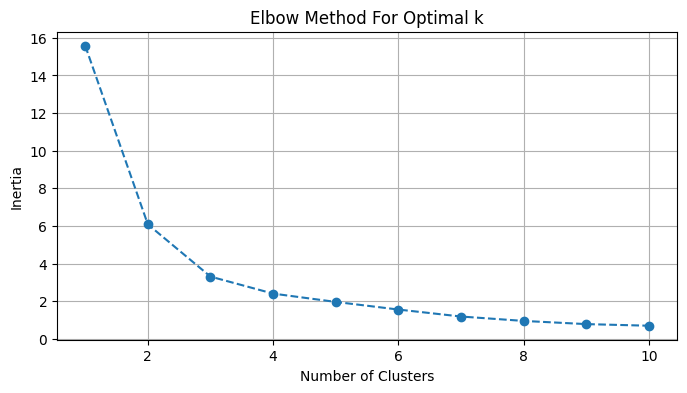

In [3]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# (2) 使用 K-Means 聚类
# (a) 使用 K-Means 算法聚类，首先设定 n_clusters=4, max_iter=50
kmeans = KMeans(n_clusters=4, max_iter=50)
kmeans.fit(rfm_df[['Recency', 'Frequency', 'Monetary']])
kmeans = KMeans(n_clusters=4, max_iter=50, n_init=10)


# (b) 使用肘部法（Elbow method）计算不同数量的聚类中心对应的总平方距离
# 其中 n_clusters=n in(1, 10), max_iter=50
inertia = []
for n in range(1, 11):
    kmeans = KMeans(n_clusters=n, max_iter=50)
    kmeans.fit(rfm_df[['Recency', 'Frequency', 'Monetary']])
    inertia.append(kmeans.inertia_)

# (c) 绘制肘部图（Elbow plot）
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.grid(True)
plt.show()